## Imports

In [31]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import LabelEncoder

## Descriptive Statistics

In [7]:
df = pd.read_csv('../data/processed/insurance_clean.csv')

In [8]:
df.head()

,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,Male,44,1,28.0,0,> 2 Years,Yes,40454.0,26.0,217,1
1,Male,76,1,3.0,0,1-2 Year,No,33536.0,26.0,183,0
2,Male,47,1,28.0,0,> 2 Years,Yes,38294.0,26.0,27,1
3,Male,21,1,11.0,1,< 1 Year,No,28619.0,152.0,203,0
4,Female,29,1,41.0,1,< 1 Year,No,27496.0,152.0,39,0


In [10]:
le_region = LabelEncoder()
le_policy = LabelEncoder()
df['Region_Code'] = le_region.fit_transform(df['Region_Code'])
df['Policy_Sales_Channel'] = le_policy.fit_transform(df['Policy_Sales_Channel'])
df.head()

,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,Male,44,1,28,0,> 2 Years,Yes,40454.0,24,217,1
1,Male,76,1,3,0,1-2 Year,No,33536.0,24,183,0
2,Male,47,1,28,0,> 2 Years,Yes,38294.0,24,27,1
3,Male,21,1,11,1,< 1 Year,No,28619.0,145,203,0
4,Female,29,1,41,1,< 1 Year,No,27496.0,145,39,0


In [12]:
# Descriptive Statistics
numerical_features = ['Age', 'Annual_Premium', 'Vintage']
df[numerical_features].describe()

,Age,Annual_Premium,Vintage
count,381109.000000,381109.000000,381109.000000
mean,38.822584,30564.389581,154.347397
std,15.511611,17213.155057,83.671304
min,20.000000,2630.000000,10.000000
25%,25.000000,24405.000000,82.000000
50%,36.000000,31669.000000,154.000000
75%,49.000000,39400.000000,227.000000
max,85.000000,540165.000000,299.000000


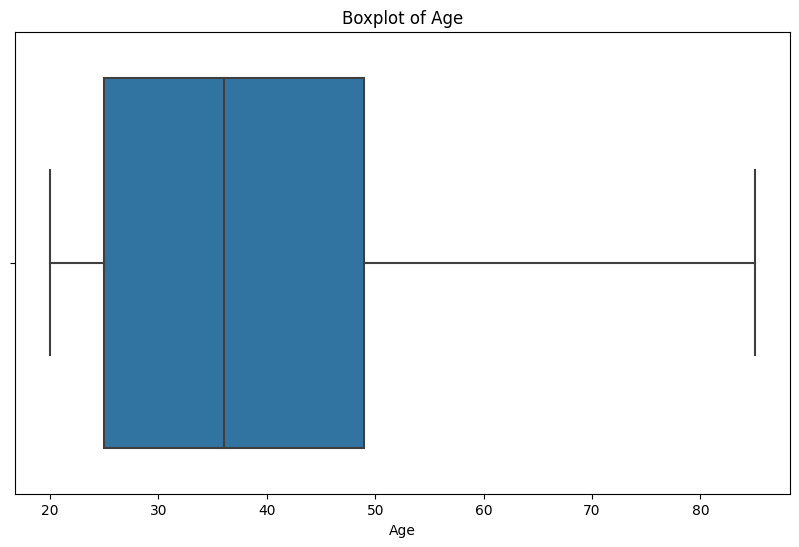

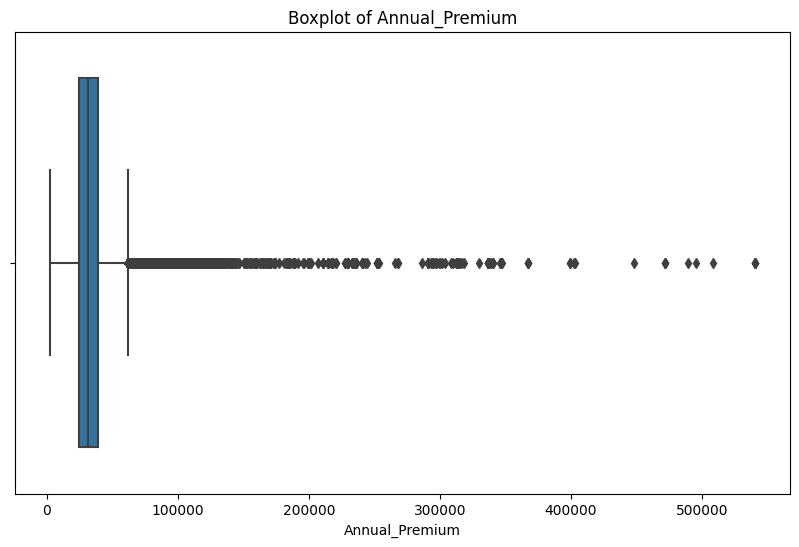

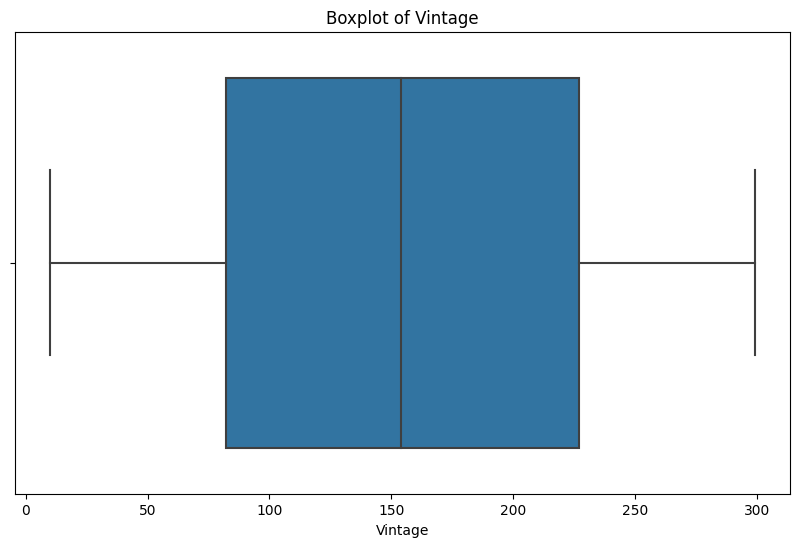

In [13]:
# Create boxplots for each numerical feature
for feature in numerical_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Boxplot of {feature}')
    plt.show()

In [14]:
# Descriptive statistics for categorical features
categorical_features = ['Gender', 'Vehicle_Age', 'Vehicle_Damage', 'Region_Code', 'Policy_Sales_Channel']

for feature in categorical_features:
    print(f"Value counts for {feature}:")
    print(df[feature].value_counts())
    print("\n")

Value counts for Gender:
Gender
Male      206089
Female    175020
Name: count, dtype: int64


Value counts for Vehicle_Age:
Vehicle_Age
1-2 Year     200316
< 1 Year     164786
> 2 Years     16007
Name: count, dtype: int64


Value counts for Vehicle_Damage:
Vehicle_Damage
Yes    192413
No     188696
Name: count, dtype: int64


Value counts for Region_Code:
Region_Code
28    106415
8      33877
46     19749
41     18263
15     13308
30     12191
29     11065
50     10243
3       9251
11      9232
36      8797
33      7654
47      7436
35      6942
6       6280
45      5605
37      5501
18      5153
48      4681
14      4678
39      4644
10      4374
21      4266
2       4038
13      4036
7       3279
12      3198
9       3101
27      2823
32      2787
43      2639
17      2617
26      2587
25      2503
24      2415
38      2026
0       2021
16      2007
31      1960
23      1960
20      1935
49      1832
4       1801
34      1664
19      1535
22      1309
40      1295
5       1279
1     

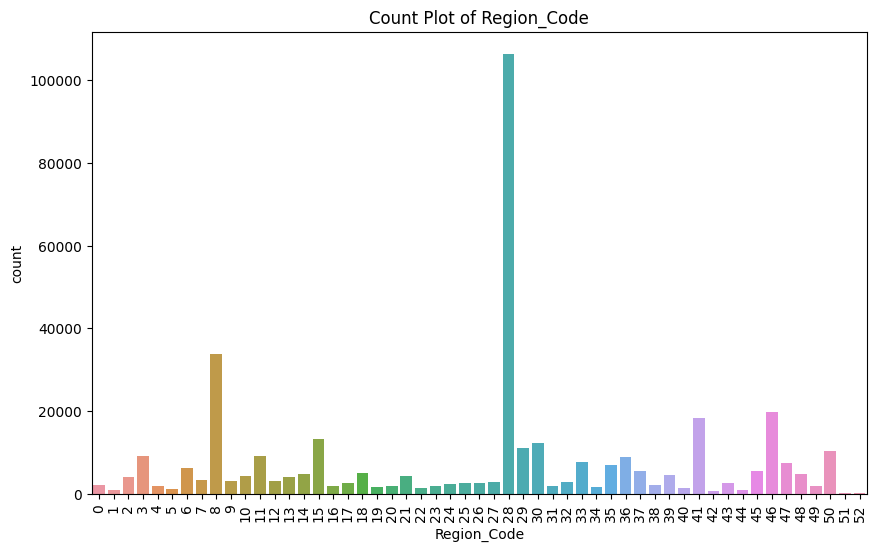

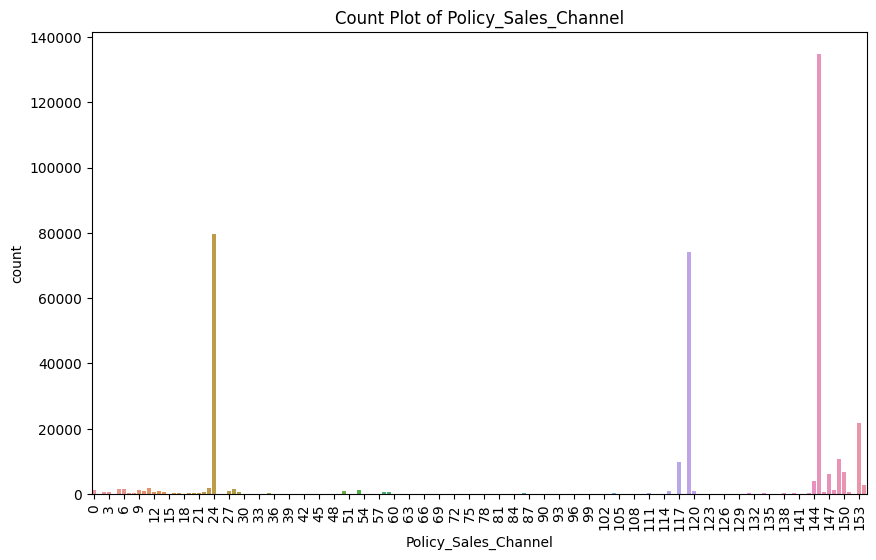

In [24]:
# Create count plots for each categorical feature
for feature in ['Region_Code', 'Policy_Sales_Channel']:
    plt.figure(figsize=(10, 6))
    ax = sns.countplot(data=df, x=feature)
    plt.title(f'Count Plot of {feature}')
    # Get current x-axis ticks
    ticks = ax.get_xticks()
    # Set new ticks to show every other tick
    if feature == 'Policy_Sales_Channel':
        ax.set_xticks(ticks[::3])
    plt.xticks(rotation=90) 
    plt.show()

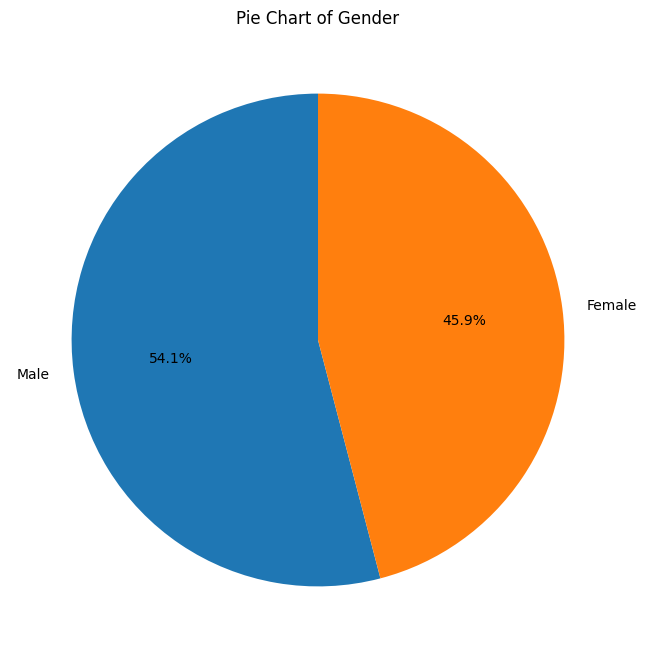

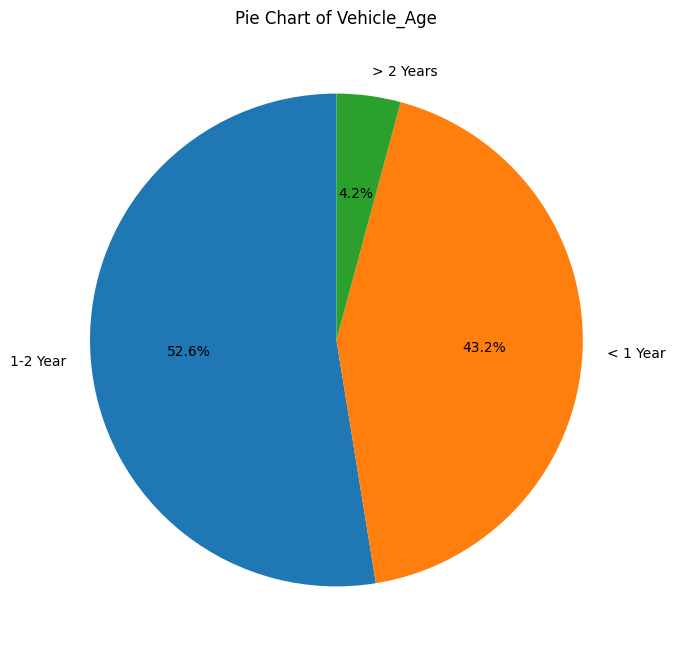

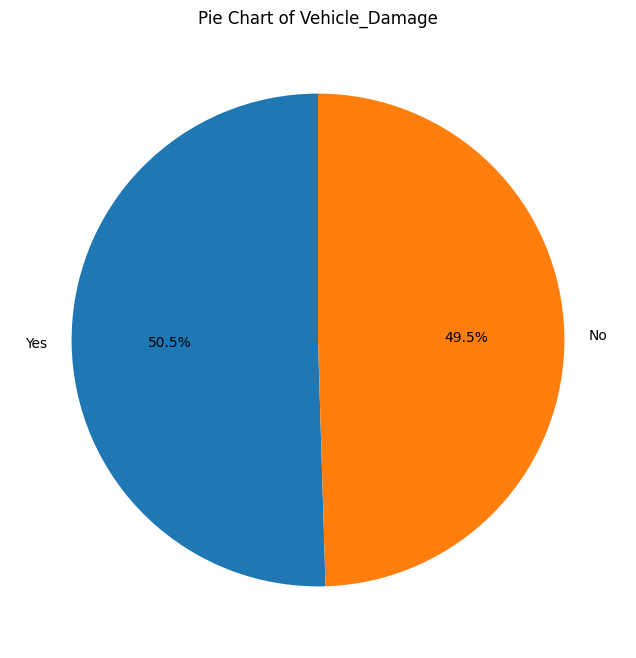

In [26]:
for feature in ['Gender', 'Vehicle_Age', 'Vehicle_Damage']:
    plt.figure(figsize=(8, 8))
    df[feature].value_counts().plot.pie(autopct='%1.1f%%', startangle=90)
    plt.title(f'Pie Chart of {feature}')
    plt.ylabel('')
    plt.show()

## Visualizations

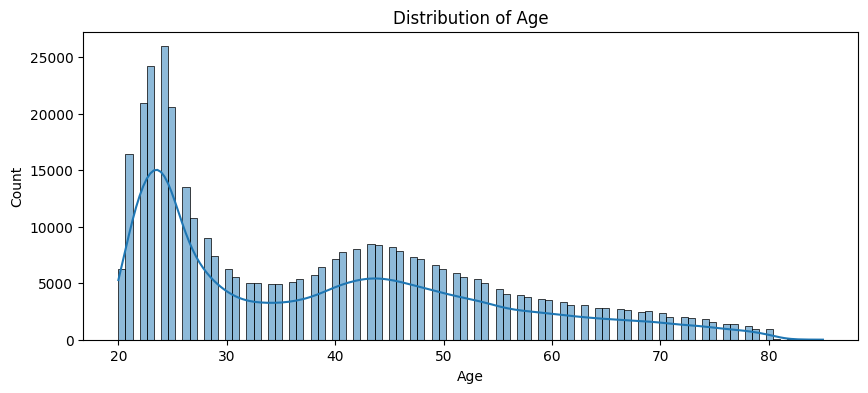

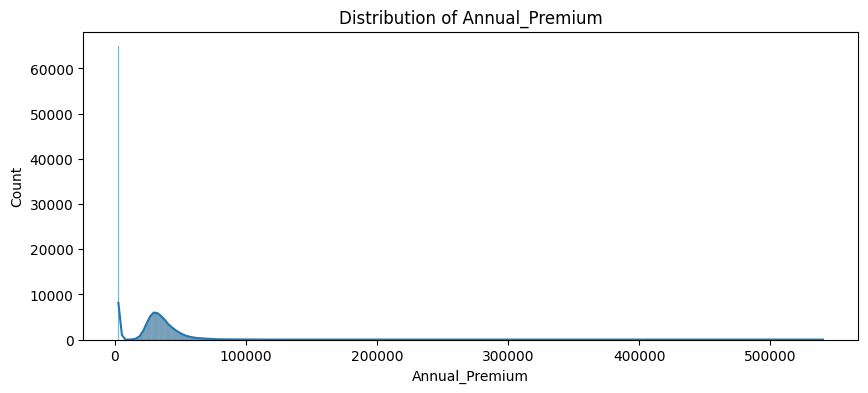

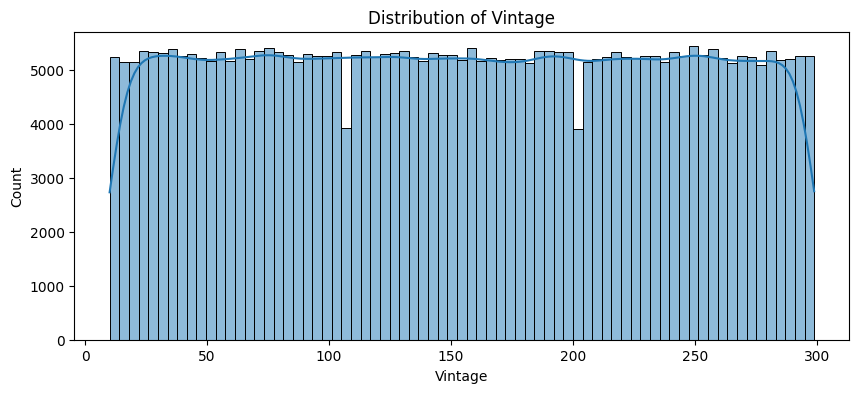

In [28]:
# Distribution plots for numerical features
for feature in numerical_features:
    plt.figure(figsize=(10, 4))
    sns.histplot(df[feature], kde=True)
    plt.title(f'Distribution of {feature}')
    plt.show()

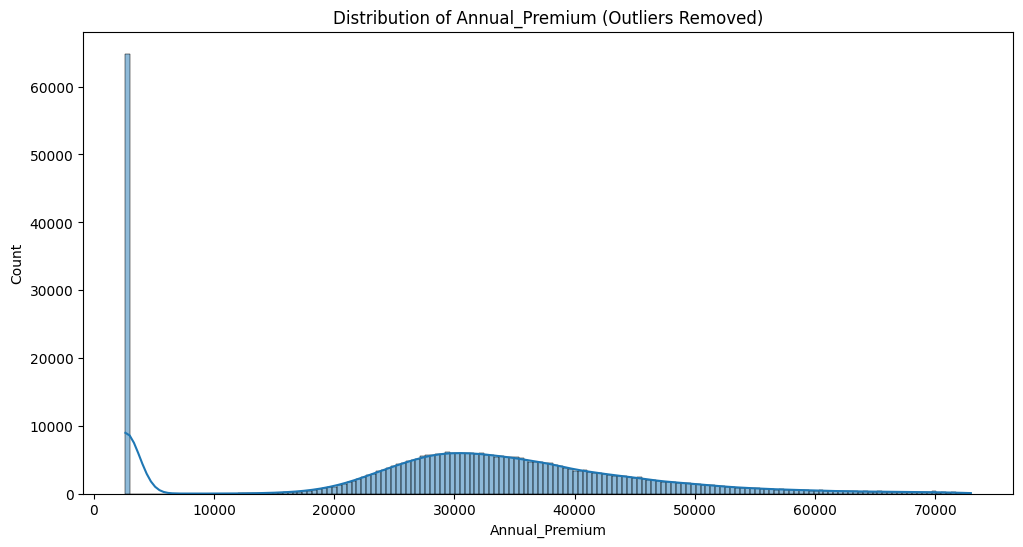

In [29]:
threshold = df['Annual_Premium'].quantile(0.99)
df_filtered = df[df['Annual_Premium'] < threshold]

# Plot the histogram with KDE for the filtered feature
plt.figure(figsize=(12, 6))
sns.histplot(df_filtered['Annual_Premium'], kde=True)
plt.title('Distribution of Annual_Premium (Outliers Removed)')
plt.xlabel('Annual_Premium')
plt.ylabel('Count')
plt.show()

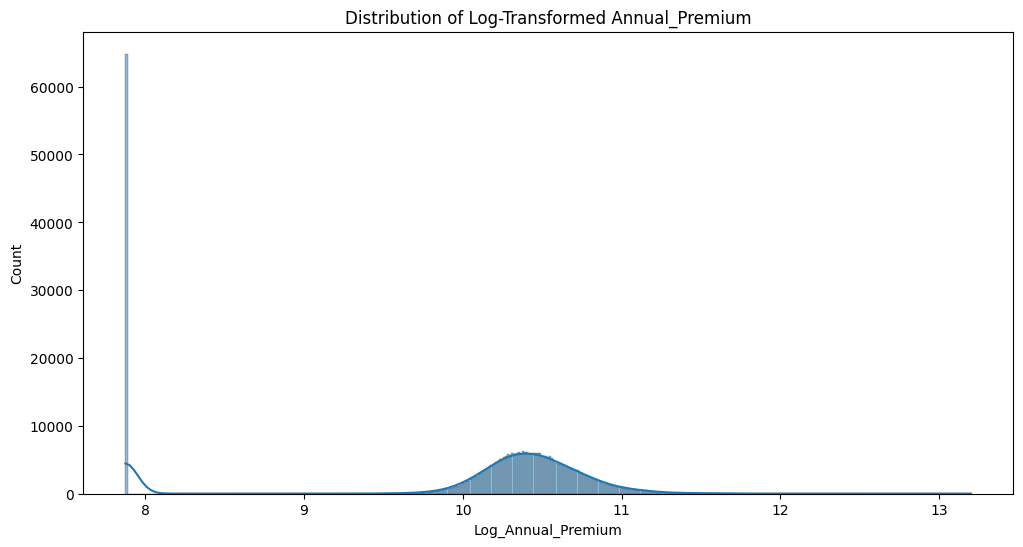

In [32]:
# Apply log transformation to 'Annual_Premium'
df['Log_Annual_Premium'] = np.log1p(df['Annual_Premium'])  # np.log1p is used to handle zero values

# Plot the histogram with KDE for the transformed feature
plt.figure(figsize=(12, 6))
sns.histplot(df['Log_Annual_Premium'], kde=True)
plt.title('Distribution of Log-Transformed Annual_Premium')
plt.xlabel('Log_Annual_Premium')
plt.ylabel('Count')
plt.show()

/var/folders/rl/4c_54ytj4d57bz0m82z25jt00000gn/T/ipykernel_14705/1999879715.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['Log_Annual_Premium'] = np.log1p(df_filtered['Annual_Premium'])


316232
381109


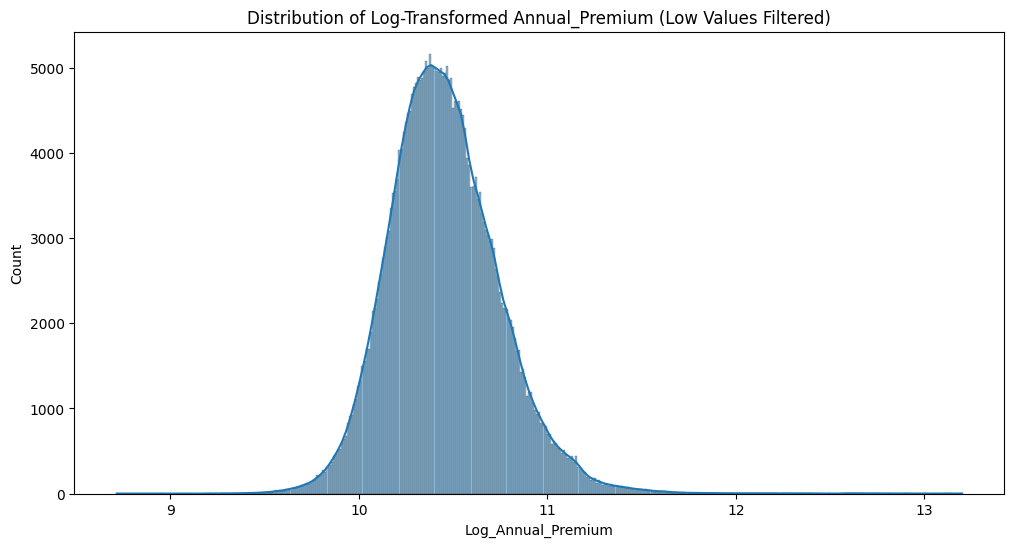

In [34]:
# Set a lower threshold to filter out extremely low values
lower_threshold = df['Annual_Premium'].quantile(0.01)
df_filtered = df[df['Annual_Premium'] > lower_threshold]

# Apply log transformation again
df_filtered['Log_Annual_Premium'] = np.log1p(df_filtered['Annual_Premium'])

print(len(df_filtered))
print(df.shape[0])

# Plot the histogram with KDE for the filtered and transformed feature
plt.figure(figsize=(12, 6))
sns.histplot(df_filtered['Log_Annual_Premium'], kde=True)
plt.title('Distribution of Log-Transformed Annual_Premium (Low Values Filtered)')
plt.xlabel('Log_Annual_Premium')
plt.ylabel('Count')
plt.show()
